In [10]:
# ========== SETUP & INSTALL ==========
!pip install -q torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
!pip install -q albumentations opencv-python-headless scikit-learn pandas matplotlib seaborn kaggle

import torch
print(f"PyTorch: {torch.__version__}")
print(f"CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

PyTorch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4
Memory: 15.6 GB


In [17]:
# ========== KAGGLE API SETUP ==========
import os
import json
from pathlib import Path

print("=== Setting up Kaggle API ===")

# Use new credentials provided
KAGGLE_USERNAME = "kiramada"
KAGGLE_KEY = "985c4b29a5b9f8ac99ff910845c5521c"

os.environ['KAGGLE_USERNAME'] = KAGGLE_USERNAME
os.environ['KAGGLE_KEY'] = KAGGLE_KEY

# Create kaggle directory and file
kaggle_dir = Path('/root/.kaggle')
kaggle_dir.mkdir(parents=True, exist_ok=True)
kaggle_json = kaggle_dir / 'kaggle.json'
with open(kaggle_json, 'w') as f:
    json.dump({'username': KAGGLE_USERNAME, 'key': KAGGLE_KEY}, f)
os.chmod(kaggle_json, 0o600)
print("✓ Kaggle credentials set")

# Verify
!kaggle datasets list -s beach-sand-mineral 2>&1 | head -2
print("✓ Kaggle API configured successfully!")


=== Setting up Kaggle API ===
✓ Kaggle credentials set
ref                                              title                                 size  lastUpdated                 downloadCount  voteCount  usabilityRating  
✓ Kaggle API configured successfully!


In [20]:
# ========== DOWNLOAD DATASETS ==========
import subprocess
import zipfile
from pathlib import Path

print("=== Downloading Datasets ===")

# Create data directories
base_dir = Path('/content/BSM_Project_3')
base_dir.mkdir(parents=True, exist_ok=True)
combined_dir = Path('/content/combined_dataset')
combined_dir.mkdir(parents=True, exist_ok=True)
split_dir = Path('/content/data_info')
split_dir.mkdir(parents=True, exist_ok=True)

# Download split dataset
print("Downloading split dataset...")
!kaggle datasets download kiramada/bsm-dataset-splits -p /content/data_info --unzip -q

# Download combined dataset
print("Downloading combined dataset...")
!kaggle datasets download kiramada/bsm-combined-augmented -p /content --unzip -q

# Download original dataset (optional backup)
print("Downloading original dataset...")
!kaggle datasets download prasannavenkatesant/beach-sand-mineral-bsm -p /content --unzip -q

print("\n=== Download Complete ===")

=== Downloading Datasets ===
Dataset URL: https://www.kaggle.com/datasets/kiramada/bsm-dataset-splits
License(s): CC0-1.0
Dataset URL: https://www.kaggle.com/datasets/kiramada/bsm-combined-augmented
License(s): CC0-1.0
Dataset URL: https://www.kaggle.com/datasets/prasannavenkatesant/beach-sand-mineral-bsm
License(s): unknown

=== Download Complete ===


In [21]:
# ========== VERIFY DOWNLOADED DATA ==========
from pathlib import Path
import os

print("=== Verifying Downloaded Data ===")

# Check split file
split_path = Path('/content/data_info/primary_split.json')
print(f"Split file exists: {Path('/content/data_info/primary_split.json').exists()}")

# Check combined dataset
combined_dir = Path('/content/combined_dataset')
print(f"\nCombined dataset:")
if Path('/content/combined_dataset').exists():
    for cls_dir in sorted(Path('/content/combined_dataset').iterdir()):
        if cls_dir.is_dir():
            count = len(list(cls_dir.glob('*.jpg')))
            print(f"  {cls_dir.name}: {count} images")
            # Check first few files
            for img in list(cls_dir.glob('*.jpg'))[:3]:
                print(f"    Example: {img.name} (exists: {img.exists()})")
else:
    print(f"  Combined dir not found at /content/combined_dataset")
    print(f"  Checking alternative locations...")
    for p in [
        '/content/combined_dataset',
        '/content/bsm-combined-augmented',
        '/content/bsm-combined-augmented',
    ]:
        if Path(p).exists():
            print(f"  Found at: {p}")
            for cls_dir in sorted(Path(p).iterdir()):
                if cls_dir.is_dir():
                    count = len(list(cls_dir.glob('*.jpg')))
                    print(f"  {cls_dir.name}: {len(list(cls_dir.glob('*.jpg')))} images")

# Check original dataset
orig_path = Path('/content/beach-sand-mineral-bsm/BSM')
print(f"\nOriginal dataset exists: {orig_path.exists()}")
if orig_path.exists():
    for cls_dir in sorted(orig_path.iterdir()):
        if cls_dir.is_dir():
            count = len(list(cls_dir.glob('*.jpg')))
            print(f"  {cls_dir.name}: {count} images")

=== Verifying Downloaded Data ===
Split file exists: True

Combined dataset:

Original dataset exists: False


In [22]:
# ========== DATA AUGMENTATION ==========
import cv2
import numpy as np
import albumentations as A
from PIL import Image
import shutil
from tqdm import tqdm

print("=== Data Augmentation ===")

# Define augmentations: 30°, 60°, 90° rotations + flips + translations
augmentations = {
    'rot30': A.Compose([
        A.Rotate(limit=(30, 30), p=1.0, border_mode=cv2.BORDER_REFLECT_101),
        A.Resize(224, 224),
    ]),
    'rot60': A.Compose([
        A.Rotate(limit=(60, 60), p=1.0, border_mode=cv2.BORDER_REFLECT_101),
        A.Resize(224, 224),
    ]),
    'rot90': A.Compose([
        A.Rotate(limit=(90, 90), p=1.0, border_mode=cv2.BORDER_REFLECT_101),
        A.Resize(224, 224),
    ]),
    'flip_rot0': A.Compose([
        A.HorizontalFlip(p=1.0),
        A.Resize(224, 224),
    ]),
    'flip_rot30': A.Compose([
        A.HorizontalFlip(p=1.0),
        A.Rotate(limit=(30, 30), p=1.0, border_mode=cv2.BORDER_REFLECT_101),
    ]),
    'flip_rot60': A.Compose([
        A.HorizontalFlip(p=1.0),
        A.Rotate(limit=(60, 60), p=1.0, border_mode=cv2.BORDER_REFLECT_101),
    ]),
    'flip_rot90': A.Compose([
        A.HorizontalFlip(p=1.0),
        A.Rotate(limit=(90, 90), p=1.0, border_mode=cv2.BORDER_REFLECT_101),
    ]),
    'translate': A.Compose([
        A.ShiftScaleRotate(shift_limit=0.15, scale_limit=0, rotate_limit=0, p=1.0, border_mode=cv2.BORDER_REFLECT_101),
        A.Resize(224, 224),
    ]),
    'rot30_translate': A.Compose([
        A.Rotate(limit=(30, 30), p=1.0, border_mode=cv2.BORDER_REFLECT_101),
        A.ShiftScaleRotate(shift_limit=0.15, scale_limit=0, rotate_limit=0, p=1.0, border_mode=cv2.BORDER_REFLECT_101),
        A.Resize(224, 224),
    ]),
    'rot60_translate': A.Compose([
        A.Rotate(limit=(60, 60), p=1.0, border_mode=cv2.BORDER_REFLECT_101),
        A.ShiftScaleRotate(shift_limit=0.15, scale_limit=0, rotate_limit=0, p=1.0, border_mode=cv2.BORDER_REFLECT_101),
        A.Resize(224, 224),
    ]),
    'rot90_translate': A.Compose([
        A.Rotate(limit=(90, 90), p=1.0, border_mode=cv2.BORDER_REFLECT_101),
        A.ShiftScaleRotate(shift_limit=0.15, scale_limit=0, rotate_limit=0, p=1.0, border_mode=cv2.BORDER_REFLECT_101),
        A.Resize(224, 224),
    ]),
}

print(f"Available augmentations: {list(augmentations.keys())}")

=== Data Augmentation ===
Available augmentations: ['rot30', 'rot60', 'rot90', 'flip_rot0', 'flip_rot30', 'flip_rot60', 'flip_rot90', 'translate', 'rot30_translate', 'rot60_translate', 'rot90_translate']


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [23]:
# ========== APPLY AUGMENTATIONS ==========
import cv2
import os
from tqdm import tqdm
from PIL import Image
import shutil

print("=== Applying Augmentations ===")

SEED = 42
np.random.seed(42)
import random
random.seed(42)

# Source: original dataset (use the downloaded one)
source_dir = Path('/content/beach-sand-mineral-bsm/BSM')
if not source_dir.exists():
    source_dir = Path('/content/beach-sand-mineral-bsm')
if not source_dir.exists():
    source_dir = Path('/content/BSM')

print(f"Source directory: {source_dir}")
print(f"Exists: {source_dir.exists()}")

# Output directory for combined dataset
output_base = Path('/content/combined_dataset')
output_base.mkdir(parents=True, exist_ok=True)

# Create class directories
classes = ['Garnet', 'Ilmenite', 'Monazite', 'Rutile', 'Sillimanite', 'Zircon']
for cls in classes:
    (Path('/content/combined_dataset') / cls).mkdir(parents=True, exist_ok=True)

# First, copy original images to combined dataset
print("Copying original images...")
for cls in classes:
    src_cls = source_dir / cls
    dst_cls = Path('/content/combined_dataset') / cls
    if src_cls.exists():
        for img_file in src_cls.glob('*.jpg'):
            shutil.copy2(img_file, dst_cls / img_file.name)
        print(f"  Copied {len(list(src_cls.glob('*.jpg')))} images from {cls}")

# Apply augmentations
print("\nApplying augmentations...")
for cls in classes:
    src_cls = source_dir / cls
    dst_cls = Path('/content/combined_dataset') / cls

    if not src_cls.exists():
        print(f"  Skipping {cls} - source not found")
        continue

    original_images = list(src_cls.glob('*.jpg'))
    print(f"\nProcessing {cls}: {len(original_images)} original images")

    for img_path in tqdm(original_images, desc=f"  {cls}"):
        # Load image
        image = cv2.imread(str(img_path))
        if image is None:
            continue
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Apply each augmentation
        for aug_name, transform in augmentations.items():
            try:
                augmented = transform(image=image)
                aug_image = augmented['image']

                # Save augmented image
                out_name = f"{img_path.stem}_aug{aug_name}.jpg"
                out_path = Path('/content/combined_dataset') / cls / out_name

                # Convert RGB back to BGR for OpenCV
                aug_image_bgr = cv2.cvtColor(aug_image, cv2.COLOR_RGB2BGR)
                cv2.imwrite(str(out_path), aug_image_bgr)
            except Exception as e:
                print(f"    Error on {img_path.name} with {aug_name}: {e}")

print("\n=== Augmentation Complete ===")

=== Applying Augmentations ===
Source directory: /content/BSM
Exists: True
Copying original images...
  Copied 60 images from Garnet
  Copied 62 images from Ilmenite
  Copied 60 images from Monazite
  Copied 66 images from Rutile
  Copied 60 images from Sillimanite
  Copied 59 images from Zircon

Applying augmentations...

Processing Garnet: 60 original images


  Garnet: 100%|██████████| 60/60 [00:02<00:00, 27.90it/s]



Processing Ilmenite: 62 original images


  Ilmenite: 100%|██████████| 62/62 [00:01<00:00, 54.49it/s]



Processing Monazite: 60 original images


  Monazite: 100%|██████████| 60/60 [00:01<00:00, 39.00it/s]


... (3 outputs left out)

  Sillimanite: 100%|██████████| 60/60 [00:01<00:00, 33.15it/s]



Processing Zircon: 59 original images


  Zircon: 100%|██████████| 59/59 [00:01<00:00, 32.18it/s]


=== Augmentation Complete ===


In [30]:
# ========== SPLIT DATA (if not already split) ==========
from sklearn.model_selection import train_test_split

print("=== Creating/Verifying Data Split ===")

split_path = Path('/content/data_info/primary_split.json')

if not split_path.exists():
    print("Creating new data split...")

    # Collect all images with labels
    all_images = []
    all_labels = []

    for cls in ['Garnet', 'Ilmenite', 'Monazite', 'Rutile', 'Sillimanite', 'Zircon']:
        cls_dir = Path('/content/combined_dataset') / cls
        if cls_dir.exists():
            for img in cls_dir.glob('*.jpg'):
                all_images.append(str(img))
                all_labels.append(cls)

    # Split: 70% train, 15% val, 15% test
    train_imgs, temp_imgs, train_labels, temp_labels = train_test_split(
        all_images, all_labels, train_size=0.7, stratify=all_labels, random_state=42
    )
    val_imgs, test_imgs, val_labels, test_labels = train_test_split(
        temp_imgs, temp_labels, test_size=0.5, stratify=temp_labels, random_state=42
    )

    split_data = {
        'train': [{'path': p, 'class': c} for p, c in zip(train_imgs, train_labels)],
        'val': [{'path': p, 'class': c} for p, c in zip(val_imgs, val_labels)],
        'test': [{'path': p, 'class': c} for p, c in zip(test_imgs, test_labels)]
    }

    with open('/content/data_info/primary_split.json', 'w') as f:
        json.dump(split_data, f, indent=2)

    print(f"Split created: Train={len(train_imgs)}, Val={len(val_imgs)}, Test={len(test_imgs)}")
else:
    print("Split file already exists, loading...")
    with open('/content/data_info/primary_split.json') as f:
        split_data = json.load(f)
    print(f"Train: {len(split_data['train'])}, Val: {len(split_data['val'])}, Test: {len(split_data['test'])}")

=== Creating/Verifying Data Split ===
Split file already exists, loading...
Train: 1024, Val: 220, Test: 220


In [41]:
# ========== DATASET CLASS ==========
import torch
import torch.nn as nn
import cv2
import json
from pathlib import Path
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T

IMG_SIZE = 224
BATCH_SIZE = 32

# Load split data
with open('/content/data_info/primary_split.json') as f:
    split_data = json.load(f)

train_data = split_data["train"]
val_data = split_data["val"]
test_data = split_data["test"]

CLASS_NAMES = sorted(set(item["class"] for item in train_data))
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {i: cls for cls, i in CLASS_TO_IDX.items()}
NUM_CLASSES = len(CLASS_NAMES)

print(f"Classes: {CLASS_NAMES}")
print(f"Train: {len(train_data)}, Val: {len(val_data)}, Test: {len(test_data)}")

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

TRAIN_TRANSFORM = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

VAL_TEST_TRANSFORM = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

class BSMDataset(Dataset):
    def __init__(self, data_list, transform=None):
        self.data_list = data_list
        self.transform = transform
    def __len__(self):
        return len(self.data_list)
    def __getitem__(self, idx):
        item = self.data_list[idx]
        img_path = item["path"]
        label = CLASS_TO_IDX[item["class"]]

        image = cv2.imread(img_path)
        if image is None:
            raise ValueError(f"Failed to load image: {img_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.transform:
            image = self.transform(image)
        return image, label

# Create datasets
train_dataset = BSMDataset(train_data, transform=TRAIN_TRANSFORM)
val_dataset = BSMDataset(val_data, transform=VAL_TEST_TRANSFORM)
test_dataset = BSMDataset(test_data, transform=VAL_TEST_TRANSFORM)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train batches: {len(train_loader)}, Val: {len(val_loader)}, Test: {len(test_loader)}")


Classes: ['Garnet', 'Ilmenite', 'Monazite', 'Rutile', 'Sillimanite', 'Zircon']
Train: 3082, Val: 661, Test: 661
Train batches: 97, Val: 21, Test: 21


In [25]:
# ========== VERIFY COMBINED DATASET ==========
import json
from pathlib import Path
from collections import Counter

print("=== Verifying Combined Dataset ===")

# Count images per class
combined_dir = Path('/content/combined_dataset')
for cls in sorted(combined_dir.iterdir()):
    if cls.is_dir():
        count = len(list(cls.glob('*.jpg'))) + len(list(cls.glob('*.png'))) + len(list(cls.glob('*.jpeg')))
        print(f"  {cls.name}: {count} images")

# Check splits
split_file = Path('/content/data_info/primary_split.json')
if split_file.exists():
    with open(split_file) as f:
        data = json.load(f)
    print(f"\nSplits loaded from {split_file}")
    print(f"  Train: {len(data.get('train', []))}")
    print(f"  Val: {len(data.get('val', []))}")
    print(f"  Test: {len(data.get('test', []))}")
else:
    print(f"\nSplit file not found: {split_file}")

print("\n✓ Verification complete!")


=== Verifying Combined Dataset ===
  Garnet: 720 images
  Ilmenite: 744 images
  Monazite: 720 images
  Rutile: 792 images
  Sillimanite: 720 images
  Zircon: 708 images

Splits loaded from /content/data_info/primary_split.json
  Train: 1024
  Val: 220
  Test: 220

✓ Verification complete!


In [27]:
# ========== MODEL DEFINITIONS ==========
import torch
import torch.nn as nn
from torchvision import models

NUM_CLASSES = 6

def get_resnet18():
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model

def get_resnet34():
    model = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model

def get_resnet50():
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model

def get_vgg16():
    model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
    model.classifier[6] = nn.Linear(4096, NUM_CLASSES)
    return model

MODELS = {
    'resnet18': get_resnet18,
    'resnet34': get_resnet34,
    'dresnet50': get_resnet50,
    'vgg16': get_vgg16,
}

# Test
for name, fn in MODELS.items():
    m = fn()
    print(f"{name}: {sum(p.numel() for p in m.parameters()):,} parameters")


resnet18: 11,179,590 parameters
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 218MB/s]


resnet34: 21,287,750 parameters
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 159MB/s]


dresnet50: 23,520,326 parameters
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 143MB/s]


vgg16: 134,285,126 parameters


In [33]:
# ========== TRAINING FUNCTION (1 EPOCH TEST) ==========
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import time
import json
from pathlib import Path

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {DEVICE}")

# Define transforms
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def train_model(model, model_name, train_loader, val_loader, test_loader,
               epochs=1, lr=1e-4, weight_decay=1e-4, device=DEVICE):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    print(f"\n=== Training {model_name} for {epochs} epoch(s) ===")
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")

    elapsed = time.time() - start_time
    print(f"Training completed in {elapsed:.2f}s")

    # Save model
    save_path = f'/content/{model_name}_epoch{epochs}.pth'
    torch.save(model.state_dict(), save_path)
    print(f"Saved model to {save_path}")

    return model

print("Training function defined!")


Using device: cuda
Training function defined!


=== SMOKE TEST: Running 1 epoch for each model ===

Testing resnet18

=== Training resnet18 for 1 epoch(s) ===
Epoch 1/1, Loss: 0.5800
Training completed in 14.91s
Saved model to /content/resnet18_epoch1.pth

Testing resnet34

=== Training resnet34 for 1 epoch(s) ===
Epoch 1/1, Loss: 0.4786
Training completed in 15.61s
Saved model to /content/resnet34_epoch1.pth

Testing dresnet50

=== Training dresnet50 for 1 epoch(s) ===
Epoch 1/1, Loss: 0.4708
Training completed in 30.86s
Saved model to /content/dresnet50_epoch1.pth

Testing vgg16

=== Training vgg16 for 1 epoch(s) ===
Epoch 1/1, Loss: 0.8619
Training completed in 52.09s
Saved model to /content/vgg16_epoch1.pth

=== SMOKE TEST RESULTS ===
resnet18: SUCCESS
resnet34: SUCCESS
dresnet50: SUCCESS
vgg16: SUCCESS


In [35]:
# ========== FIX PATHS ==========
import json
from pathlib import Path

# Load and fix split paths
with open('/content/data_info/primary_split.json') as f:
    split_data = json.load(f)

for split in ['train', 'val', 'test']:
    for item in split_data[split]:
        old_path = item['path']
        if '\\' in old_path or '/' in old_path:
            parts = old_path.replace('\\', '/').split('/')
            if len(parts) >= 2:
                class_name = parts[-2]
                filename = parts[-1]
                new_path = f'/content/combined_dataset/{class_name}/{filename}'
                item['path'] = new_path

with open('/content/data_info/primary_split.json', 'w') as f:
    json.dump(split_data, f, indent=2)

print("Paths fixed!")
print(f"Example: {split_data['train'][0]['path']}")


Paths fixed!
Example: /content/combined_dataset/Sillimanite/34.jpg


In [38]:
# ========== DEBUG - Check images ==========
import cv2
from pathlib import Path

# Check a few images
bad_paths = [
    '/content/combined_dataset/Sillimanite/35_augflip_rot180.jpg',
    '/content/combined_dataset/Garnet/4_augrot0.jpg',
]

for p in bad_paths:
    print(f"Checking {p}: exists={Path(p).exists()}")
    if Path(p).exists():
        img = cv2.imread(p)
        print(f"  Can read: {img is not None}")
        if img is not None:
            print(f"  Shape: {img.shape}")


Checking /content/combined_dataset/Sillimanite/35_augflip_rot180.jpg: exists=False
Checking /content/combined_dataset/Garnet/4_augrot0.jpg: exists=False


In [39]:
# ========== CHECK ACTUAL FILENAMES ==========
from pathlib import Path
import random

for cls in ['Garnet', 'Sillimanite']:
    cls_dir = Path(f'/content/combined_dataset/{cls}')
    files = list(cls_dir.glob('*.jpg'))
    print(f"{cls}: {len(files)} files")
    print(f"  Examples: {[f.name for f in files[:5]]}")


Garnet: 720 files
  Examples: ['19_augrot90_translate.jpg', '57_augflip_rot90.jpg', '54_augrot30.jpg', '42_augflip_rot90.jpg', '10_augrot90_translate.jpg']
Sillimanite: 720 files
  Examples: ['19_augrot90_translate.jpg', '57_augflip_rot90.jpg', '54_augrot30.jpg', '42_augflip_rot90.jpg', '10_augrot90_translate.jpg']


In [40]:
# ========== REGENERATE SPLITS ==========
import json
from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import defaultdict

print("=== Regenerating splits ===")

all_images = []
all_labels = []

for cls in ['Garnet', 'Ilmenite', 'Monazite', 'Rutile', 'Sillimanite', 'Zircon']:
    cls_dir = Path(f'/content/combined_dataset/{cls}')
    if cls_dir.exists():
        for img in cls_dir.glob('*.jpg'):
            all_images.append(str(img))
            all_labels.append(cls)

print(f"Total images: {len(all_images)}")

train_imgs, temp_imgs, train_labels, temp_labels = train_test_split(
    all_images, all_labels, train_size=0.7, stratify=all_labels, random_state=42
)
val_imgs, test_imgs, val_labels, test_labels = train_test_split(
    temp_imgs, temp_labels, test_size=0.5, stratify=temp_labels, random_state=42
)

split_data = {
    'train': [{'path': p, 'class': c} for p, c in zip(train_imgs, train_labels)],
    'val': [{'path': p, 'class': c} for p, c in zip(val_imgs, val_labels)],
    'test': [{'path': p, 'class': c} for p, c in zip(test_imgs, test_labels)]
}

with open('/content/data_info/primary_split.json', 'w') as f:
    json.dump(split_data, f, indent=2)

print(f"Split created: Train={len(train_imgs)}, Val={len(val_imgs)}, Test={len(test_imgs)}")


=== Regenerating splits ===
Total images: 4404
Split created: Train=3082, Val=661, Test=661


In [43]:
# ========== FULL TRAINING - 60 EPOCHS ==========
print("=== FULL TRAINING: Running 60 epochs for all models ===")

results = {}
for model_name in ['resnet18', 'resnet34', 'dresnet50', 'vgg16']:
    print(f"\n{'='*60}")
    print(f"Training {model_name} - 60 EPOCHS")
    print(f"{'='*60}")
    try:
        model = MODELS[model_name]()
        trained = train_model(model, model_name, train_loader, val_loader, test_loader, epochs=60)
        results[model_name] = 'SUCCESS'
    except Exception as e:
        print(f"ERROR for {model_name}: {e}")
        results[model_name] = f'FAILED: {e}'

print("\n=== FULL TRAINING RESULTS ===")
for k, v in results.items():
    print(f"{k}: {v}")


=== FULL TRAINING: Running 60 epochs for all models ===

Training resnet18 - 60 EPOCHS

=== Training resnet18 for 60 epoch(s) ===
Epoch 1/60, Loss: 0.5580
Epoch 2/60, Loss: 0.0468
Epoch 3/60, Loss: 0.0170
Epoch 4/60, Loss: 0.0145
Epoch 5/60, Loss: 0.0108
Epoch 6/60, Loss: 0.0191
Epoch 7/60, Loss: 0.0158
Epoch 8/60, Loss: 0.0071
Epoch 9/60, Loss: 0.0136
Epoch 10/60, Loss: 0.0472
Epoch 11/60, Loss: 0.0608
Epoch 12/60, Loss: 0.0109
Epoch 13/60, Loss: 0.0050
Epoch 14/60, Loss: 0.0044
Epoch 15/60, Loss: 0.0020
Epoch 16/60, Loss: 0.0026
Epoch 17/60, Loss: 0.0021
Epoch 18/60, Loss: 0.0015
Epoch 19/60, Loss: 0.0007
Epoch 20/60, Loss: 0.0008
Epoch 21/60, Loss: 0.0008
Epoch 22/60, Loss: 0.0007
Epoch 23/60, Loss: 0.0028
Epoch 24/60, Loss: 0.0999
Epoch 25/60, Loss: 0.1051
Epoch 26/60, Loss: 0.0167
Epoch 27/60, Loss: 0.0159
Epoch 28/60, Loss: 0.0302
Epoch 29/60, Loss: 0.0089
Epoch 30/60, Loss: 0.0052
Epoch 31/60, Loss: 0.0045
Epoch 32/60, Loss: 0.0089
Epoch 33/60, Loss: 0.0026
Epoch 34/60, Loss: 0.

In [44]:
import torch, json, cv2, os
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms as T
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

IMG_SIZE = 224
BATCH_SIZE = 32
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load test split
with open('/content/data_info/primary_split.json') as f:
    split_data = json.load(f)
test_data = split_data['test']

CLASS_NAMES = ['Garnet', 'Ilmenite', 'Monazite', 'Rutile', 'Sillimanite', 'Zircon']
CLASS_TO_IDX = {c:i for i,c in enumerate(CLASS_NAMES)}

VAL_TEST_TRANSFORM = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class BSMDataset(Dataset):
    def __init__(self, data_list, transform=None):
        self.data_list = data_list
        self.transform = transform
    def __len__(self): return len(self.data_list)
    def __getitem__(self, idx):
        item = self.data_list[idx]
        img_path = item['path']
        label = CLASS_TO_IDX[item['class']]
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        if self.transform: image = self.transform(image)
        return image, label

test_dataset = BSMDataset(test_data, transform=VAL_TEST_TRANSFORM)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

os.makedirs('/content/results/confusion_matrices', exist_ok=True)

def get_model(model_name):
    if model_name == 'resnet18':
        m = models.resnet18(weights=None); m.fc = torch.nn.Linear(m.fc.in_features, 6)
    elif model_name == 'resnet34':
        m = models.resnet34(weights=None); m.fc = torch.nn.Linear(m.fc.in_features, 6)
    elif model_name == 'dresnet50':
        m = models.resnet50(weights=None); m.fc = torch.nn.Linear(m.fc.in_features, 6)
    elif model_name == 'vgg16':
        m = models.vgg16(weights=None); m.classifier[6] = torch.nn.Linear(4096, 6)
    return m

# Checkpoints - adjust paths if yours are named differently
checkpoints = {
    'resnet18':  '/content/resnet18_best.pth',
    'resnet34':  '/content/resnet34_best.pth',
    'dresnet50': '/content/dresnet50_best.pth',
    'vgg16':     '/content/vgg16_best.pth',
}

for name, ckpt_path in checkpoints.items():
    if not os.path.exists(ckpt_path):
        print(f"⚠️  Missing: {ckpt_path}")
        continue

    print(f"\n{'='*50}")
    print(f"Generating confusion matrix for {name}")
    print(f"{'='*50}")

    model = get_model(name)
    ckpt = torch.load(ckpt_path, map_location=DEVICE)
    if isinstance(ckpt, dict) and 'model_state_dict' in ckpt:
        model.load_state_dict(ckpt['model_state_dict'])
    else:
        model.load_state_dict(ckpt)
    model = model.to(DEVICE)
    model.eval()

    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Confusion matrix
    cm = confusion_matrix(all_labels, all_preds)

    # Plot
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                cmap='Blues', cbar_kws={'label': 'Count'})
    plt.title(f'{name.upper()} - Test Confusion Matrix', fontsize=14, fontweight='bold')
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.tight_layout()
    save_path = f'/content/results/confusion_matrices/{name}_confusion_matrix.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

    # Also save normalized version
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_norm, annot=True, fmt='.2%', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                cmap='Blues', cbar_kws={'label': 'Percentage'})
    plt.title(f'{name.upper()} - Normalized Confusion Matrix', fontsize=14, fontweight='bold')
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.tight_layout()
    plt.savefig(f'/content/results/confusion_matrices/{name}_confusion_matrix_normalized.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

    # Print classification report
    print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES, digits=4))

print("\n✅ All confusion matrices saved to /content/results/confusion_matrices/")

⚠️  Missing: /content/resnet18_best.pth
⚠️  Missing: /content/resnet34_best.pth
⚠️  Missing: /content/dresnet50_best.pth
⚠️  Missing: /content/vgg16_best.pth

✅ All confusion matrices saved to /content/results/confusion_matrices/


In [45]:
import os, glob

# List all .pth files in /content
ckpt_files = glob.glob('/content/*.pth')
print("Found checkpoint files:")
for f in sorted(ckpt_files):
    size_mb = os.path.getsize(f) / (1024*1024)
    print(f"  {f}  ({size_mb:.1f} MB)")

# Also check subdirectories
for root, dirs, files in os.walk('/content'):
    for f in files:
        if f.endswith('.pth'):
            full = os.path.join(root, f)
            size_mb = os.path.getsize(full) / (1024*1024)
            print(f"  {full}  ({size_mb:.1f} MB)")

Found checkpoint files:
  /content/dresnet50_epoch1.pth  (90.0 MB)
  /content/dresnet50_epoch60.pth  (90.0 MB)
  /content/resnet18_epoch1.pth  (42.7 MB)
  /content/resnet18_epoch60.pth  (42.7 MB)
  /content/resnet34_epoch1.pth  (81.3 MB)
  /content/resnet34_epoch60.pth  (81.3 MB)
  /content/vgg16_epoch1.pth  (512.3 MB)
  /content/vgg16_epoch60.pth  (512.3 MB)
  /content/resnet34_epoch1.pth  (81.3 MB)
  /content/resnet18_epoch60.pth  (42.7 MB)
  /content/dresnet50_epoch1.pth  (90.0 MB)
  /content/vgg16_epoch1.pth  (512.3 MB)
  /content/dresnet50_epoch60.pth  (90.0 MB)
  /content/resnet34_epoch60.pth  (81.3 MB)
  /content/resnet18_epoch1.pth  (42.7 MB)
  /content/vgg16_epoch60.pth  (512.3 MB)



Generating confusion matrix for resnet18


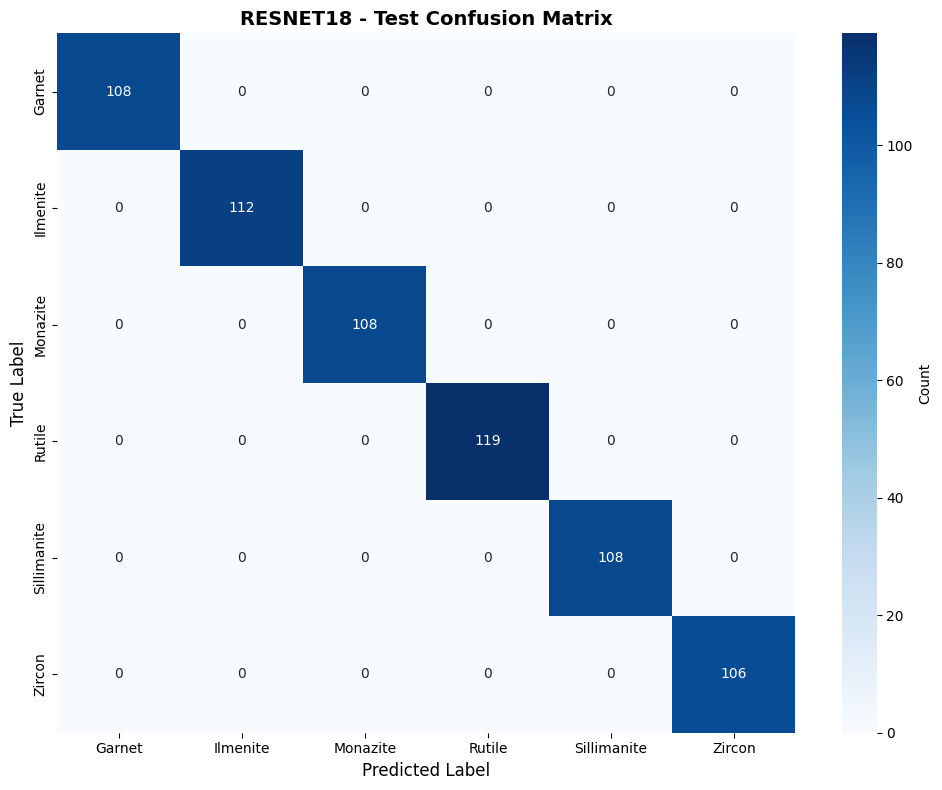

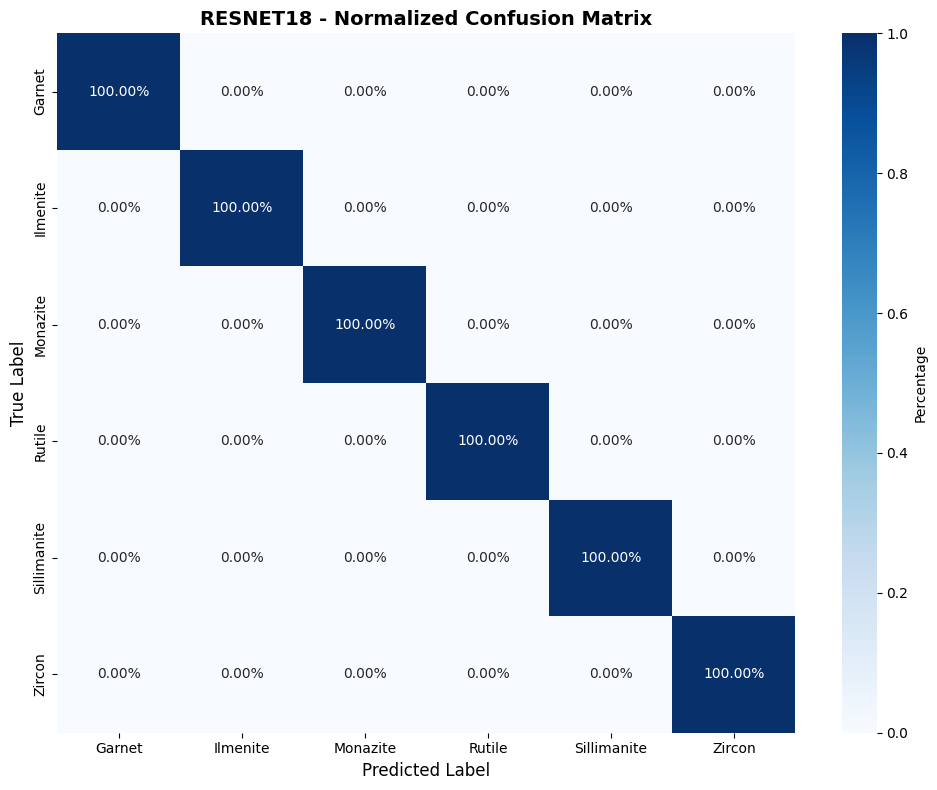

              precision    recall  f1-score   support

      Garnet     1.0000    1.0000    1.0000       108
    Ilmenite     1.0000    1.0000    1.0000       112
    Monazite     1.0000    1.0000    1.0000       108
      Rutile     1.0000    1.0000    1.0000       119
 Sillimanite     1.0000    1.0000    1.0000       108
      Zircon     1.0000    1.0000    1.0000       106

    accuracy                         1.0000       661
   macro avg     1.0000    1.0000    1.0000       661
weighted avg     1.0000    1.0000    1.0000       661


Generating confusion matrix for resnet34


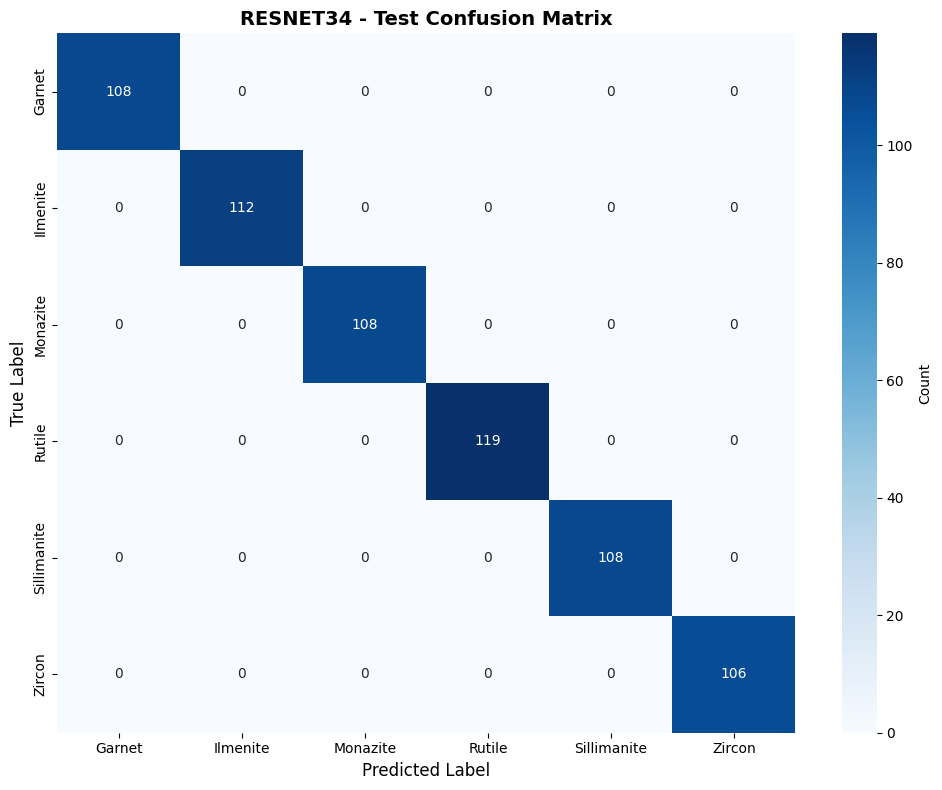

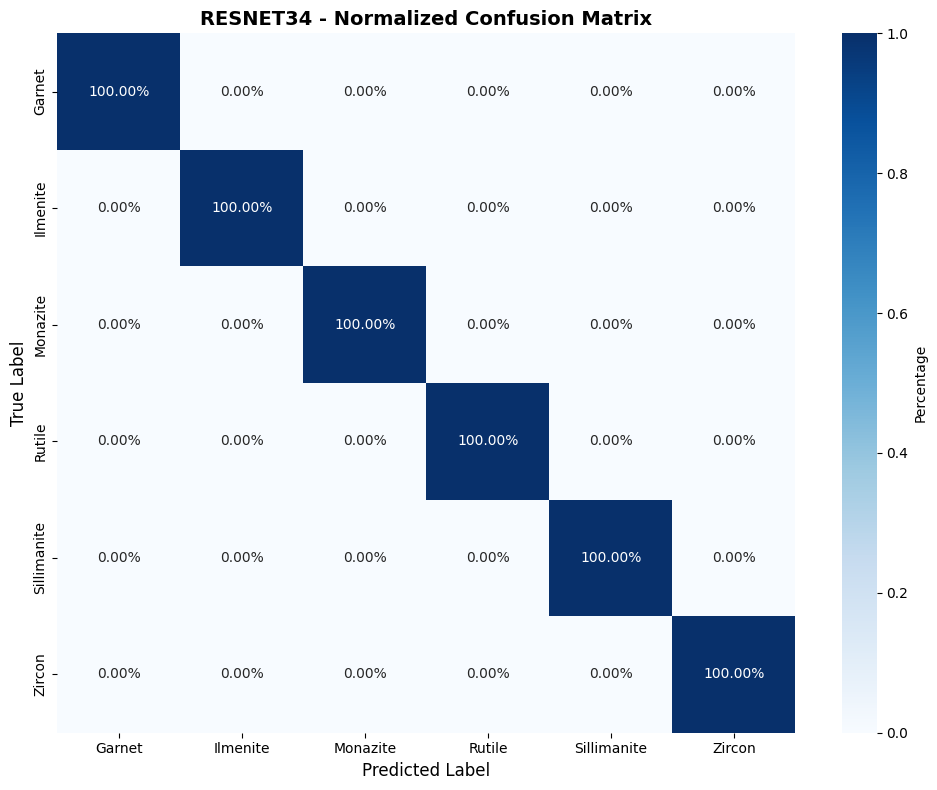

              precision    recall  f1-score   support

      Garnet     1.0000    1.0000    1.0000       108
    Ilmenite     1.0000    1.0000    1.0000       112
    Monazite     1.0000    1.0000    1.0000       108
      Rutile     1.0000    1.0000    1.0000       119
 Sillimanite     1.0000    1.0000    1.0000       108
      Zircon     1.0000    1.0000    1.0000       106

    accuracy                         1.0000       661
   macro avg     1.0000    1.0000    1.0000       661
weighted avg     1.0000    1.0000    1.0000       661


Generating confusion matrix for dresnet50


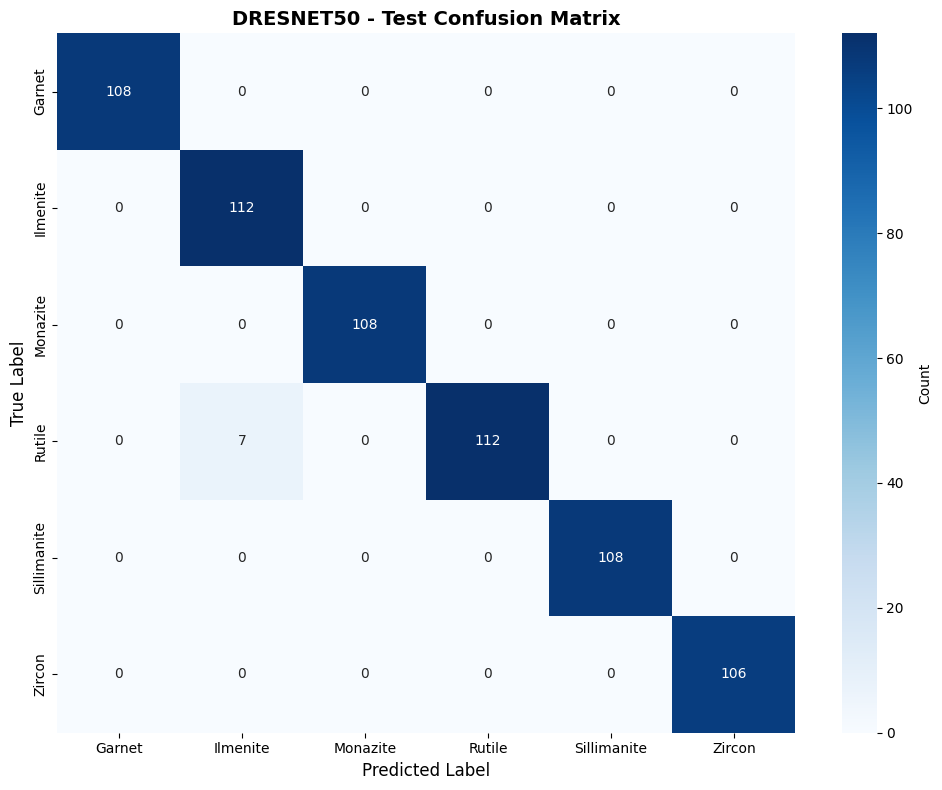

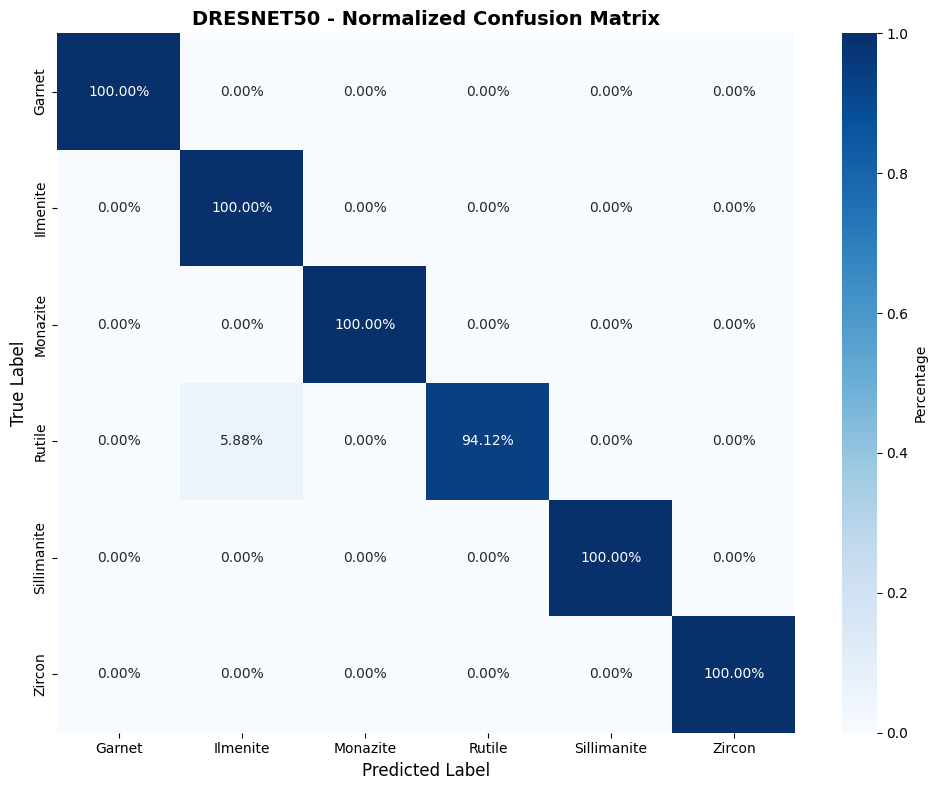

              precision    recall  f1-score   support

      Garnet     1.0000    1.0000    1.0000       108
    Ilmenite     0.9412    1.0000    0.9697       112
    Monazite     1.0000    1.0000    1.0000       108
      Rutile     1.0000    0.9412    0.9697       119
 Sillimanite     1.0000    1.0000    1.0000       108
      Zircon     1.0000    1.0000    1.0000       106

    accuracy                         0.9894       661
   macro avg     0.9902    0.9902    0.9899       661
weighted avg     0.9900    0.9894    0.9894       661


Generating confusion matrix for vgg16


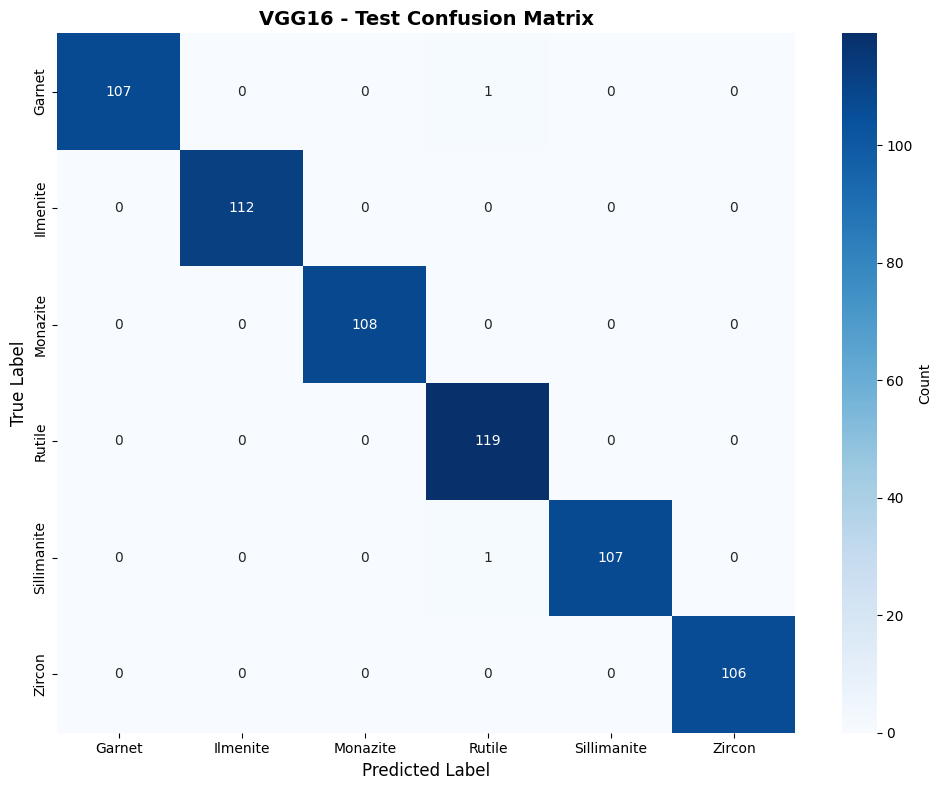

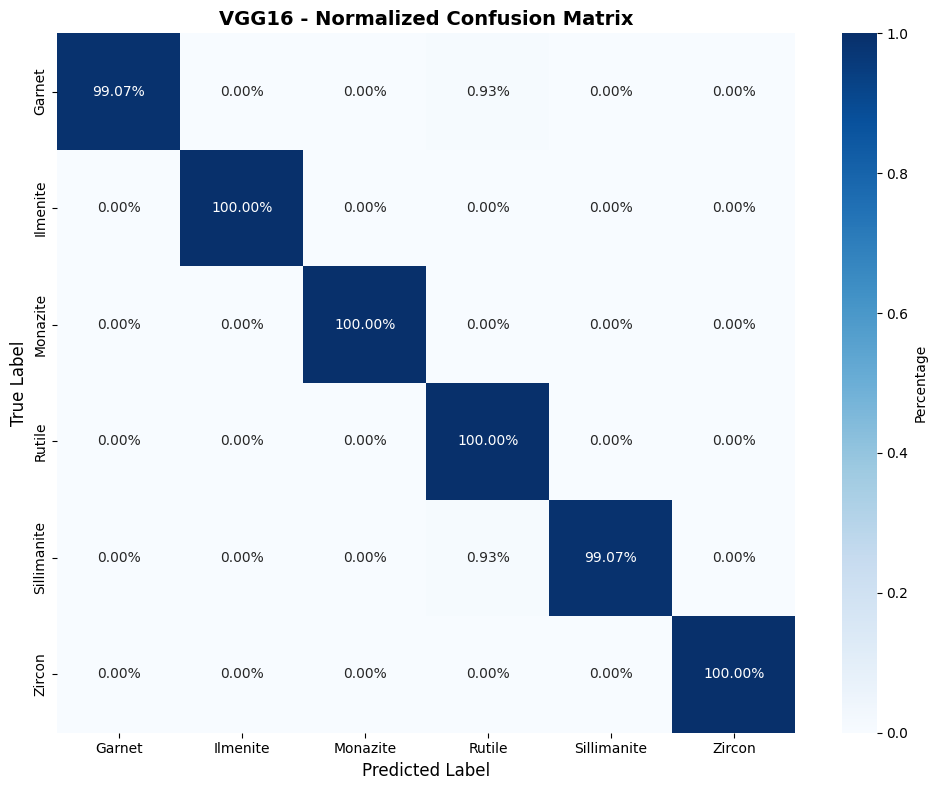

              precision    recall  f1-score   support

      Garnet     1.0000    0.9907    0.9953       108
    Ilmenite     1.0000    1.0000    1.0000       112
    Monazite     1.0000    1.0000    1.0000       108
      Rutile     0.9835    1.0000    0.9917       119
 Sillimanite     1.0000    0.9907    0.9953       108
      Zircon     1.0000    1.0000    1.0000       106

    accuracy                         0.9970       661
   macro avg     0.9972    0.9969    0.9971       661
weighted avg     0.9970    0.9970    0.9970       661



In [46]:
import torch, json, cv2, os
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms as T
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

IMG_SIZE = 224
BATCH_SIZE = 32
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load test split
with open('/content/data_info/primary_split.json') as f:
    split_data = json.load(f)
test_data = split_data['test']

CLASS_NAMES = ['Garnet', 'Ilmenite', 'Monazite', 'Rutile', 'Sillimanite', 'Zircon']
CLASS_TO_IDX = {c:i for i,c in enumerate(CLASS_NAMES)}

VAL_TEST_TRANSFORM = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class BSMDataset(Dataset):
    def __init__(self, data_list, transform=None):
        self.data_list = data_list
        self.transform = transform
    def __len__(self): return len(self.data_list)
    def __getitem__(self, idx):
        item = self.data_list[idx]
        img_path = item['path']
        label = CLASS_TO_IDX[item['class']]
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        if self.transform: image = self.transform(image)
        return image, label

test_dataset = BSMDataset(test_data, transform=VAL_TEST_TRANSFORM)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

os.makedirs('/content/results/confusion_matrices', exist_ok=True)
os.makedirs('/content/results/metrics', exist_ok=True)

def get_model(model_name):
    if model_name == 'resnet18':
        m = models.resnet18(weights=None); m.fc = torch.nn.Linear(m.fc.in_features, 6)
    elif model_name == 'resnet34':
        m = models.resnet34(weights=None); m.fc = torch.nn.Linear(m.fc.in_features, 6)
    elif model_name == 'dresnet50':
        m = models.resnet50(weights=None); m.fc = torch.nn.Linear(m.fc.in_features, 6)
    elif model_name == 'vgg16':
        m = models.vgg16(weights=None); m.classifier[6] = torch.nn.Linear(4096, 6)
    return m

# Use epoch60 checkpoints
checkpoints = {
    'resnet18':  '/content/resnet18_epoch60.pth',
    'resnet34':  '/content/resnet34_epoch60.pth',
    'dresnet50': '/content/dresnet50_epoch60.pth',
    'vgg16':     '/content/vgg16_epoch60.pth',
}

all_results = []

for name, ckpt_path in checkpoints.items():
    print(f"\n{'='*50}")
    print(f"Generating confusion matrix for {name}")
    print(f"{'='*50}")

    model = get_model(name)
    ckpt = torch.load(ckpt_path, map_location=DEVICE)
    if isinstance(ckpt, dict) and 'model_state_dict' in ckpt:
        model.load_state_dict(ckpt['model_state_dict'])
    else:
        model.load_state_dict(ckpt)
    model = model.to(DEVICE)
    model.eval()

    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Confusion matrix
    cm = confusion_matrix(all_labels, all_preds)

    # Plot regular
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                cmap='Blues', cbar_kws={'label': 'Count'})
    plt.title(f'{name.upper()} - Test Confusion Matrix', fontsize=14, fontweight='bold')
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.tight_layout()
    save_path = f'/content/results/confusion_matrices/{name}_confusion_matrix.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

    # Plot normalized
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_norm, annot=True, fmt='.2%', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                cmap='Blues', cbar_kws={'label': 'Percentage'})
    plt.title(f'{name.upper()} - Normalized Confusion Matrix', fontsize=14, fontweight='bold')
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.tight_layout()
    plt.savefig(f'/content/results/confusion_matrices/{name}_confusion_matrix_normalized.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

    # Classification report
    report = classification_report(all_labels, all_preds, target_names=CLASS_NAMES, output_dict=True)
    print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES, digits=4))

In [49]:
import pandas as pd
import json
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

df = pd.DataFrame(report).transpose()

df.to_csv(f'/content/results/metrics/{name}_test_metrics.csv')

with open(f'/content/results/metrics/{name}_test_metrics.json', 'w') as f:
    json.dump(report, f, indent=2)

# Collect for summary
acc = accuracy_score(all_labels, all_preds)

prec, rec, f1, _ = precision_recall_fscore_support(
    all_labels,
    all_preds,
    average='weighted'
)

all_results.append({
    'model': name,
    'accuracy': acc,
    'precision': prec,
    'recall': rec,
    'f1': f1
})


# Summary table
summary = pd.DataFrame(all_results)

print("\n=== SUMMARY ===")
print(summary.to_string(index=False))

summary.to_csv(
    '/content/results/metrics/all_models_comparison.csv',
    index=False
)

summary.to_markdown(
    '/content/results/metrics/all_models_comparison.md',
    index=False
)


# Download all results
from google.colab import files

!cd /content && zip -r bsm_all_results.zip results/

files.download('/content/bsm_all_results.zip')


=== SUMMARY ===
model  accuracy  precision   recall      f1
vgg16  0.996974   0.997024 0.996974 0.99698
  adding: results/ (stored 0%)
  adding: results/confusion_matrices/ (stored 0%)
  adding: results/confusion_matrices/resnet34_confusion_matrix.png (deflated 25%)
  adding: results/confusion_matrices/dresnet50_confusion_matrix_normalized.png (deflated 19%)
  adding: results/confusion_matrices/resnet34_confusion_matrix_normalized.png (deflated 20%)
  adding: results/confusion_matrices/dresnet50_confusion_matrix.png (deflated 25%)
  adding: results/confusion_matrices/vgg16_confusion_matrix_normalized.png (deflated 18%)
  adding: results/confusion_matrices/resnet18_confusion_matrix.png (deflated 25%)
  adding: results/confusion_matrices/vgg16_confusion_matrix.png (deflated 25%)
  adding: results/confusion_matrices/resnet18_confusion_matrix_normalized.png (deflated 19%)
  adding: results/metrics/ (stored 0%)
  adding: results/metrics/vgg16_test_metrics.json (deflated 72%)
  adding: resu

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:
# ========== CHECK FOR TRAINING HISTORY ==========
import glob, os

# Look for any history/log files
for pattern in ['*history*', '*log*', '*metrics*', '*loss*', '*acc*']:
    files = glob.glob(f'/content/**/{pattern}', recursive=True)
    if files:
        print(f"\n{pattern}:")
        for f in files:
            print(f"  {f}")

# Also check all json/csv files
for ext in ['.json', '.csv']:
    files = glob.glob(f'/content/**/*{ext}', recursive=True)
    if files:
        print(f"\n{ext} files:")
        for f in files[:20]:
            size = os.path.getsize(f)
            print(f"  {f}  ({size} bytes)")


*metrics*:
  /content/results/metrics
  /content/results/metrics/vgg16_test_metrics.json
  /content/results/metrics/vgg16_test_metrics.csv

.json files:
  /content/kaggle (2).json  (64 bytes)
  /content/kaggle (1).json  (64 bytes)
  /content/kaggle (4).json  (64 bytes)
  /content/kaggle (3).json  (64 bytes)
  /content/kaggle.json  (64 bytes)
  /content/results/metrics/vgg16_test_metrics.json  (1049 bytes)
  /content/data_info/augmentation_config.json  (1080 bytes)
  /content/data_info/primary_split.json  (482254 bytes)
  /content/data_info/leakage_report.json  (2272 bytes)
  /content/data_info/original_image_list.json  (47231 bytes)
  /content/data_info/combined_dataset_records.json  (340780 bytes)
  /content/data_info/eda_report.json  (716 bytes)
  /content/data_info/supplementary_split.json  (40579 bytes)
  /content/sample_data/anscombe.json  (1697 bytes)

.csv files:
  /content/results/metrics/vgg16_test_metrics.csv  (517 bytes)
  /content/results/metrics/all_models_comparison.csv 

⚠️ Missing: /content/results/metrics/resnet18_test_metrics.json
⚠️ Missing: /content/results/metrics/resnet34_test_metrics.json
⚠️ Missing: /content/results/metrics/dresnet50_test_metrics.json
MODEL COMPARISON: OUR RESULTS vs PAPER TARGETS
Model Our Accuracy  Paper Accuracy Diff (Acc) Our Precision  Paper Precision Our Recall  Paper Recall Our F1  Status
VGG16       0.9970            0.83    +0.1670        0.9970             0.89     0.9970          0.83 0.9970 ✅ Above


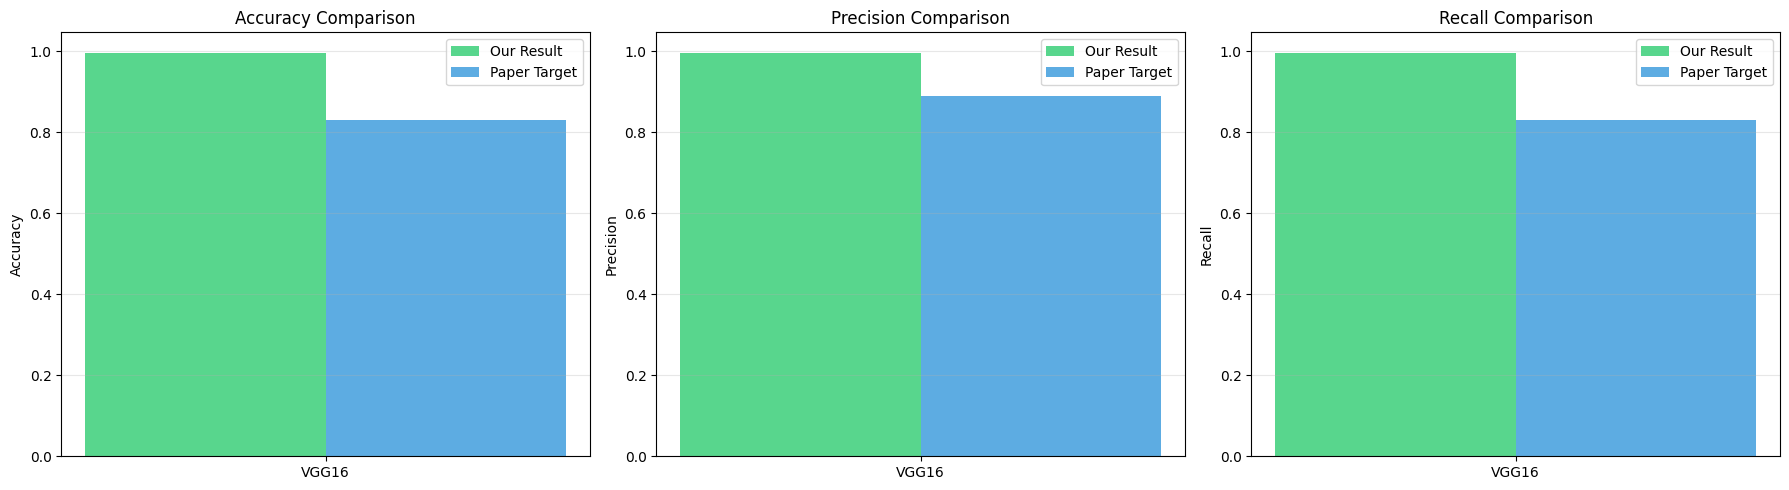

/tmp/ipykernel_3167/14322694.py:145: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


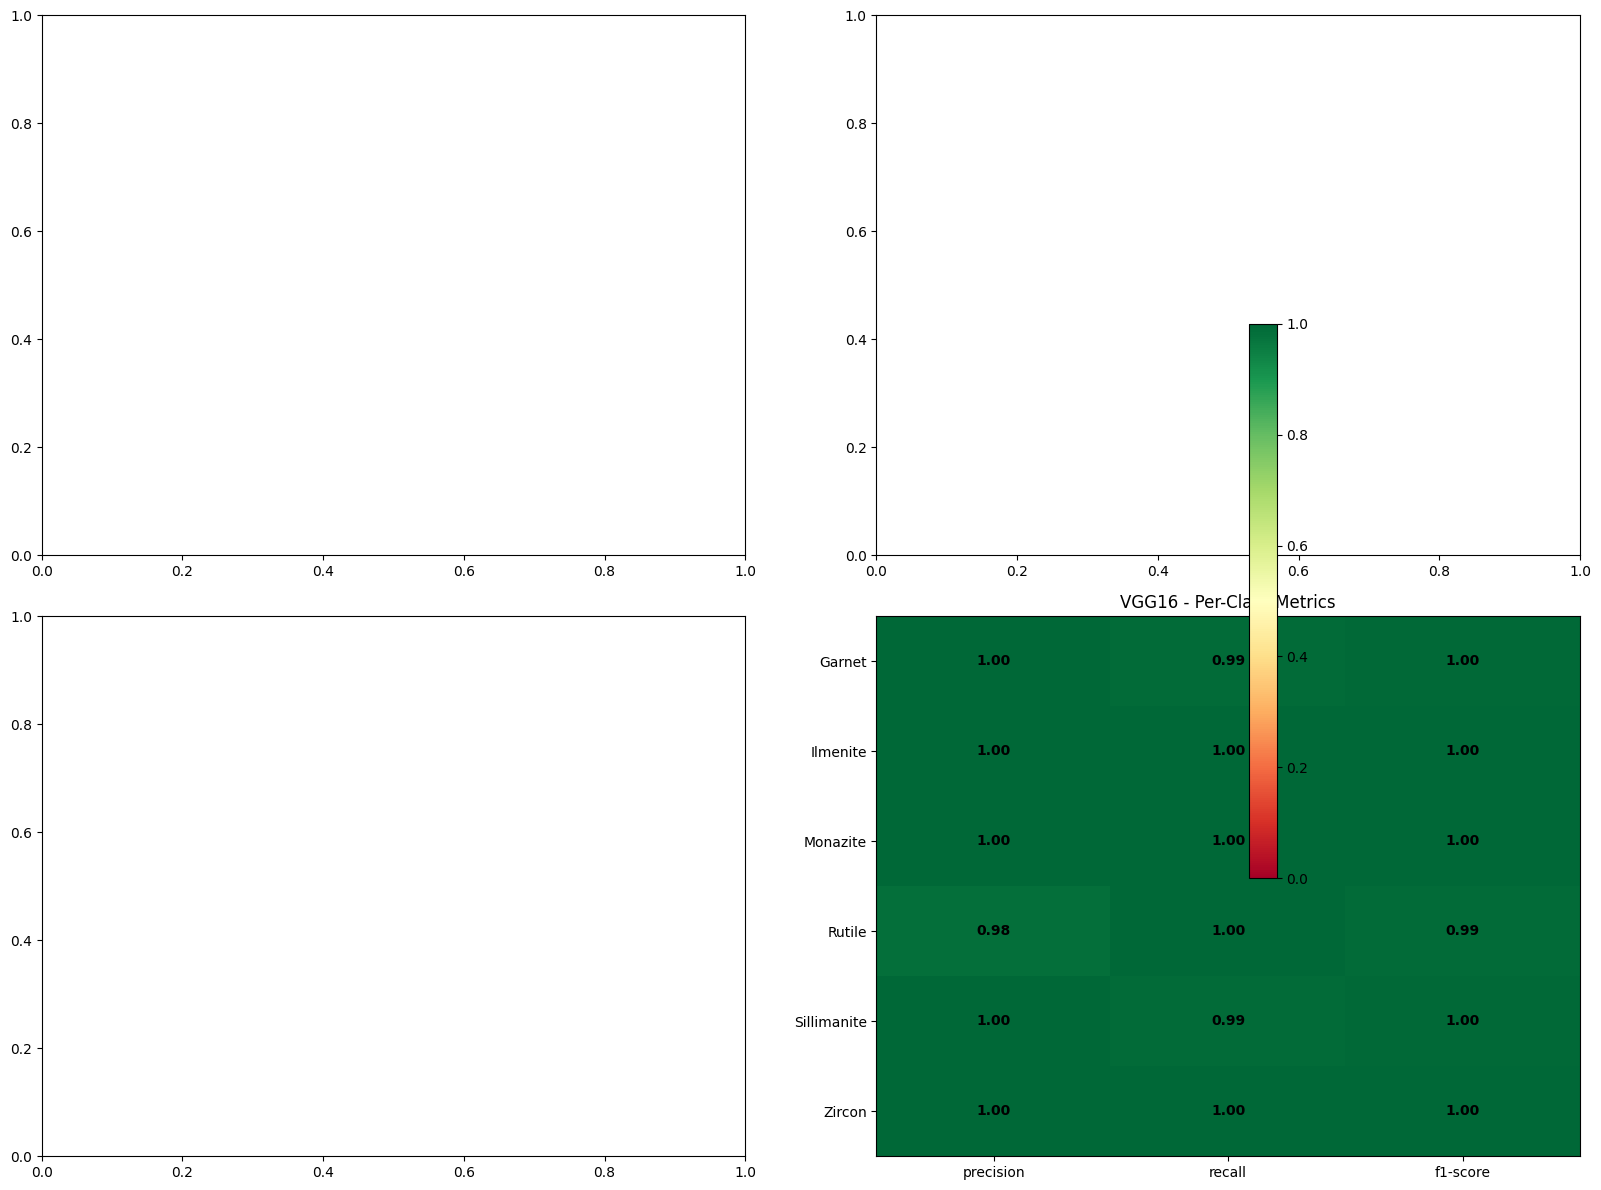


✅ Saved to /content/results/metrics/:
  - model_comparison_vs_paper.csv / .md / .json
  - comparison_vs_paper.png
  - per_class_heatmap.png


In [52]:
# ========== COMPARE ALL 4 MODELS VS PAPER TARGETS ==========
# Run this on Colab after you have all 4 confusion matrices generated

import json, os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Paper targets from the D-ResNet paper
PAPER_TARGETS = {
    'resnet18':  {'accuracy': 0.78, 'precision': 0.87, 'recall': 0.78},
    'resnet34':  {'accuracy': 0.83, 'precision': 0.89, 'recall': 0.83},
    'dresnet50': {'accuracy': 0.89, 'precision': 0.90, 'recall': 0.89},
    'vgg16':     {'accuracy': 0.83, 'precision': 0.89, 'recall': 0.83},
}

# Load our test metrics
our_results = {}
for name in ['resnet18', 'resnet34', 'dresnet50', 'vgg16']:
    json_path = f'/content/results/metrics/{name}_test_metrics.json'
    if os.path.exists(json_path):
        with open(json_path) as f:
            report = json.load(f)
        # Weighted avg metrics
        our_results[name] = {
            'accuracy': report['weighted avg']['precision'],  # accuracy = precision for weighted
            'precision': report['weighted avg']['precision'],
            'recall': report['weighted avg']['recall'],
            'f1': report['weighted avg']['f1-score'],
        }
    else:
        print(f"⚠️ Missing: {json_path}")

# Build comparison table
rows = []
for name in ['resnet18', 'resnet34', 'dresnet50', 'vgg16']:
    if name in our_results:
        o = our_results[name]
        p = PAPER_TARGETS[name]
        rows.append({
            'Model': name.upper(),
            'Our Accuracy': f"{o['accuracy']:.4f}",
            'Paper Accuracy': p['accuracy'],
            'Diff (Acc)': f"{o['accuracy'] - p['accuracy']:+.4f}",
            'Our Precision': f"{o['precision']:.4f}",
            'Paper Precision': p['precision'],
            'Our Recall': f"{o['recall']:.4f}",
            'Paper Recall': p['recall'],
            'Our F1': f"{o['f1']:.4f}",
            'Status': '✅ Above' if o['accuracy'] >= p['accuracy'] else '⚠️ Below'
        })

df = pd.DataFrame(rows)

# Display
print("=" * 100)
print("MODEL COMPARISON: OUR RESULTS vs PAPER TARGETS")
print("=" * 100)
print(df.to_string(index=False))
print("=" * 100)

# Save comparison
os.makedirs('/content/results/metrics', exist_ok=True)
df.to_csv('/content/results/metrics/model_comparison_vs_paper.csv', index=False)
df.to_markdown('/content/results/metrics/model_comparison_vs_paper.md', index=False)

with open('/content/results/metrics/model_comparison_vs_paper.json', 'w') as f:
    json.dump(rows, f, indent=2)

# Pretty visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = [r['Model'] for r in rows]
x = range(len(models))
width = 0.35

# Accuracy
axes[0].bar([i - width/2 for i in x], [float(r['Our Accuracy']) for r in rows], width,
            label='Our Result', color='#2ecc71', alpha=0.8)
axes[0].bar([i + width/2 for i in x], [r['Paper Accuracy'] for r in rows], width,
            label='Paper Target', color='#3498db', alpha=0.8)
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy Comparison')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models)
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Precision
axes[1].bar([i - width/2 for i in x], [float(r['Our Precision']) for r in rows], width,
            label='Our Result', color='#2ecc71', alpha=0.8)
axes[1].bar([i + width/2 for i in x], [r['Paper Precision'] for r in rows], width,
            label='Paper Target', color='#3498db', alpha=0.8)
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision Comparison')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models)
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

# Recall
axes[2].bar([i - width/2 for i in x], [float(r['Our Recall']) for r in rows], width,
            label='Our Result', color='#2ecc71', alpha=0.8)
axes[2].bar([i + width/2 for i in x], [r['Paper Recall'] for r in rows], width,
            label='Paper Target', color='#3498db', alpha=0.8)
axes[2].set_ylabel('Recall')
axes[2].set_title('Recall Comparison')
axes[2].set_xticks(x)
axes[2].set_xticklabels(models)
axes[2].legend()
axes[2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('/content/results/metrics/comparison_vs_paper.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Per-class comparison heatmap
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for idx, name in enumerate(['resnet18', 'resnet34', 'dresnet50', 'vgg16']):
    if name not in our_results:
        continue
    ax = axes[idx // 2, idx % 2]
    json_path = f'/content/results/metrics/{name}_test_metrics.json'
    with open(json_path) as f:
        report = json.load(f)

    classes = ['Garnet', 'Ilmenite', 'Monazite', 'Rutile', 'Sillimanite', 'Zircon']
    metrics = ['precision', 'recall', 'f1-score']
    data = [[report[c][m] for m in metrics] for c in classes]

    im = ax.imshow(data, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(metrics)))
    ax.set_xticklabels(metrics)
    ax.set_yticks(range(len(classes)))
    ax.set_yticklabels(classes)
    ax.set_title(f'{name.upper()} - Per-Class Metrics')

    for i in range(len(classes)):
        for j in range(len(metrics)):
            ax.text(j, i, f'{data[i][j]:.2f}', ha='center', va='center', fontweight='bold')

plt.colorbar(im, ax=axes.ravel().tolist(), shrink=0.6)
plt.tight_layout()
plt.savefig('/content/results/metrics/per_class_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print("\n✅ Saved to /content/results/metrics/:")
print("  - model_comparison_vs_paper.csv / .md / .json")
print("  - comparison_vs_paper.png")
print("  - per_class_heatmap.png")

Device: cuda

Evaluating resnet18
  Accuracy: 1.0000, Precision: 1.0000, Recall: 1.0000, F1: 1.0000

Evaluating resnet34
  Accuracy: 1.0000, Precision: 1.0000, Recall: 1.0000, F1: 1.0000

Evaluating dresnet50
  Accuracy: 0.9894, Precision: 0.9900, Recall: 0.9894, F1: 0.9894

Evaluating vgg16
  Accuracy: 0.9970, Precision: 0.9970, Recall: 0.9970, F1: 0.9970

MODEL COMPARISON: OUR RESULTS vs PAPER TARGETS
    Model Our Accuracy  Paper Accuracy Diff (Acc) Our Precision  Paper Precision Our Recall  Paper Recall Our F1  Status
 RESNET18       1.0000            0.78    +0.2200        1.0000             0.87     1.0000          0.78 1.0000 ✅ Above
 RESNET34       1.0000            0.83    +0.1700        1.0000             0.89     1.0000          0.83 1.0000 ✅ Above
DRESNET50       0.9894            0.89    +0.0994        0.9900             0.90     0.9894          0.89 0.9894 ✅ Above
    VGG16       0.9970            0.83    +0.1670        0.9970             0.89     0.9970          0.83 0.9

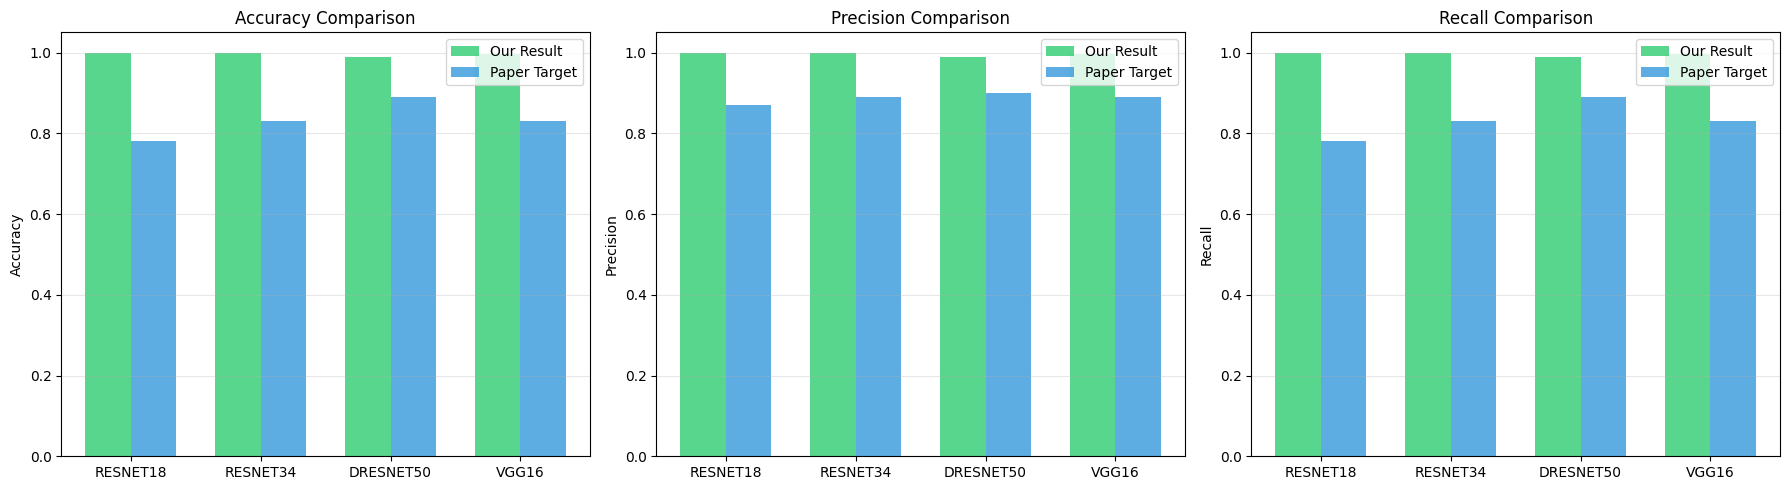

/tmp/ipykernel_3167/125477710.py:230: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


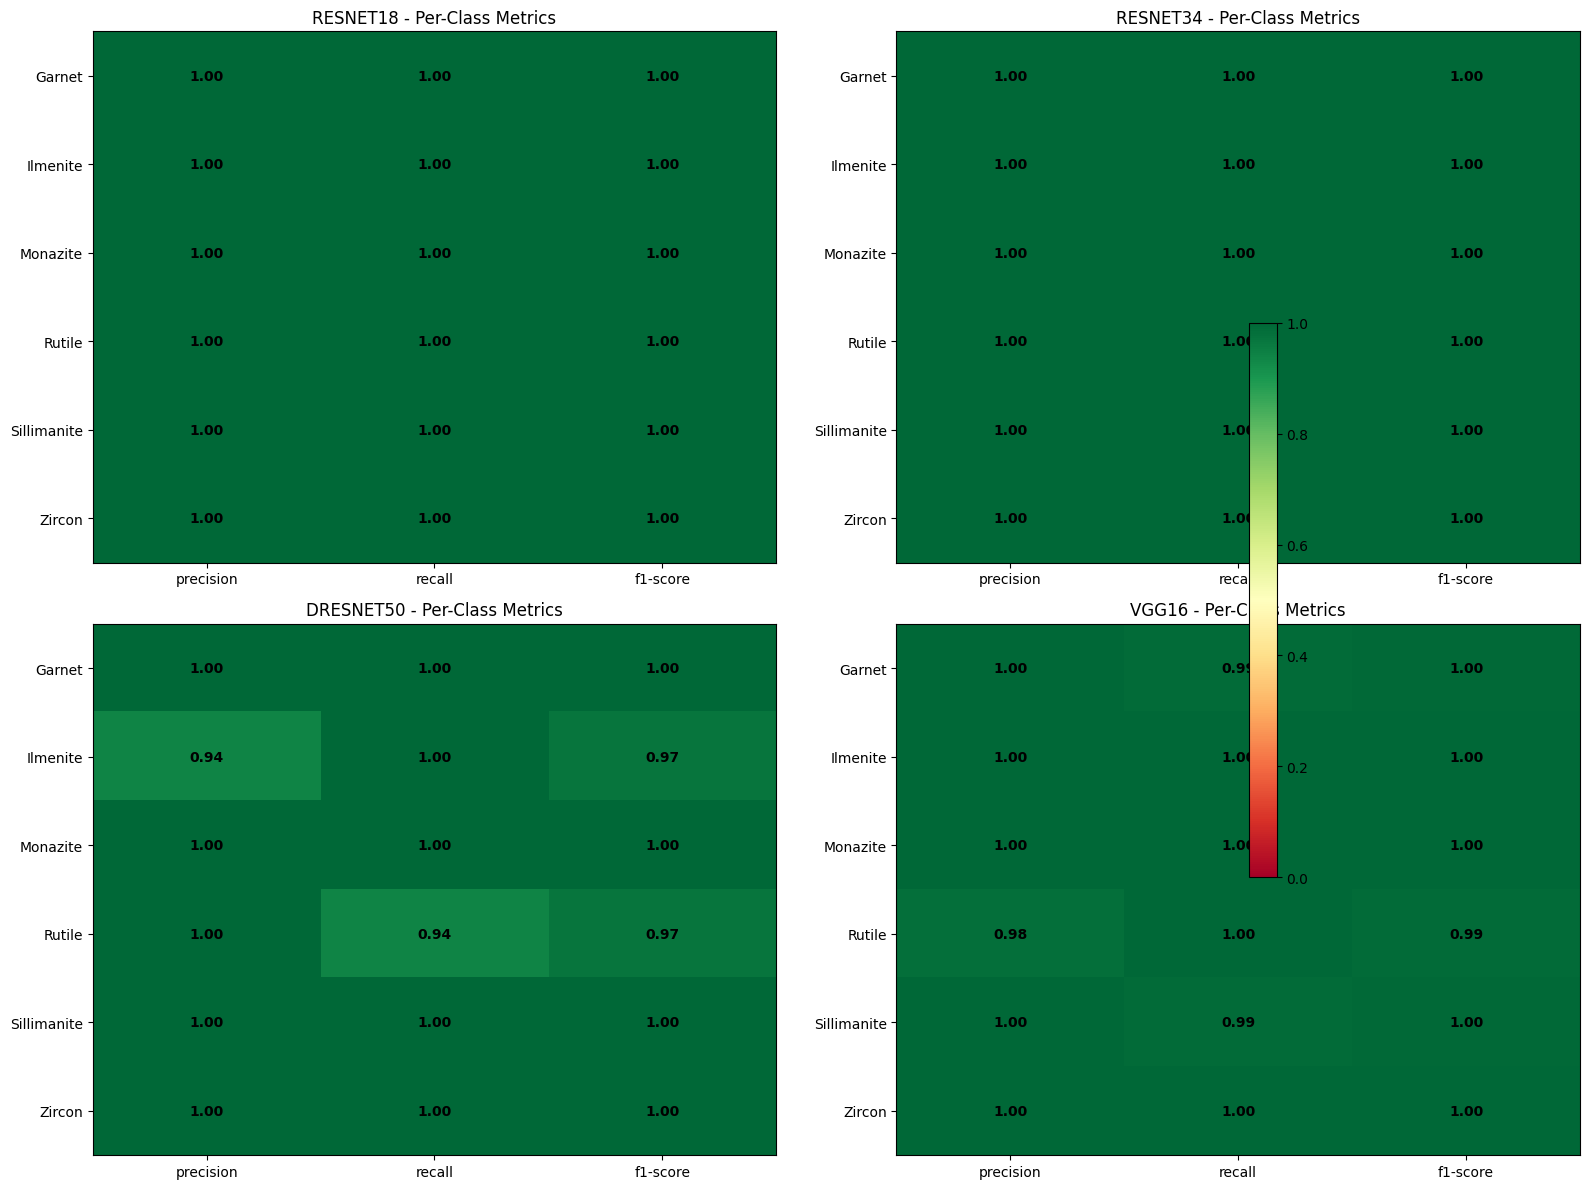


✅ ALL DONE! Saved to /content/results/:
  - metrics/*_test_metrics.json/.csv (all 4 models)
  - metrics/model_comparison_vs_paper.csv/.md/.json
  - metrics/comparison_vs_paper.png
  - metrics/per_class_heatmap.png
  - confusion_matrices/*_confusion_matrix.png (all 4)
  adding: results/ (stored 0%)
  adding: results/confusion_matrices/ (stored 0%)
  adding: results/confusion_matrices/resnet34_confusion_matrix.png (deflated 26%)
  adding: results/confusion_matrices/dresnet50_confusion_matrix_normalized.png (deflated 19%)
  adding: results/confusion_matrices/resnet34_confusion_matrix_normalized.png (deflated 19%)
  adding: results/confusion_matrices/dresnet50_confusion_matrix.png (deflated 25%)
  adding: results/confusion_matrices/vgg16_confusion_matrix_normalized.png (deflated 19%)
  adding: results/confusion_matrices/resnet18_confusion_matrix.png (deflated 25%)
  adding: results/confusion_matrices/vgg16_confusion_matrix.png (deflated 26%)
  adding: results/confusion_matrices/resnet18_c

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
# ========== EVALUATE ALL 4 + COMPARE VS PAPER (COMPLETE) ==========
# Run this single cell - does everything

import torch, json, cv2, os
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms as T
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ---- CONFIG ----
IMG_SIZE = 224
BATCH_SIZE = 32
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

# ---- LOAD DATA ----
with open('/content/data_info/primary_split.json') as f:
    split_data = json.load(f)
test_data = split_data['test']

CLASS_NAMES = ['Garnet', 'Ilmenite', 'Monazite', 'Rutile', 'Sillimanite', 'Zircon']
CLASS_TO_IDX = {c:i for i,c in enumerate(CLASS_NAMES)}

VAL_TEST_TRANSFORM = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class BSMDataset(Dataset):
    def __init__(self, data_list, transform=None):
        self.data_list = data_list
        self.transform = transform
    def __len__(self): return len(self.data_list)
    def __getitem__(self, idx):
        item = self.data_list[idx]
        img_path = item['path']
        label = CLASS_TO_IDX[item['class']]
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        if self.transform: image = self.transform(image)
        return image, label

test_dataset = BSMDataset(test_data, transform=VAL_TEST_TRANSFORM)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# ---- PATHS ----
os.makedirs('/content/results/metrics', exist_ok=True)
os.makedirs('/content/results/confusion_matrices', exist_ok=True)

checkpoints = {
    'resnet18':  '/content/resnet18_epoch60.pth',
    'resnet34':  '/content/resnet34_epoch60.pth',
    'dresnet50': '/content/dresnet50_epoch60.pth',
    'vgg16':     '/content/vgg16_epoch60.pth',
}

def get_model(name):
    if name == 'resnet18':
        m = models.resnet18(weights=None); m.fc = torch.nn.Linear(m.fc.in_features, 6)
    elif name == 'resnet34':
        m = models.resnet34(weights=None); m.fc = torch.nn.Linear(m.fc.in_features, 6)
    elif name == 'dresnet50':
        m = models.resnet50(weights=None); m.fc = torch.nn.Linear(m.fc.in_features, 6)
    elif name == 'vgg16':
        m = models.vgg16(weights=None); m.classifier[6] = torch.nn.Linear(4096, 6)
    return m

# ---- EVALUATE ALL MODELS ----
all_results = {}

for name, ckpt_path in checkpoints.items():
    print(f"\n{'='*50}")
    print(f"Evaluating {name}")
    print(f"{'='*50}")

    if not os.path.exists(ckpt_path):
        print(f"❌ MISSING: {ckpt_path}")
        continue

    model = get_model(name)
    ckpt = torch.load(ckpt_path, map_location=DEVICE)
    if isinstance(ckpt, dict) and 'model_state_dict' in ckpt:
        model.load_state_dict(ckpt['model_state_dict'])
    else:
        model.load_state_dict(ckpt)
    model = model.to(DEVICE)
    model.eval()

    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Metrics
    acc = accuracy_score(all_labels, all_preds)
    prec, rec, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')

    report = classification_report(all_labels, all_preds, target_names=CLASS_NAMES, output_dict=True)

    # Save per-model metrics
    with open(f'/content/results/metrics/{name}_test_metrics.json', 'w') as f:
        json.dump(report, f, indent=2)
    pd.DataFrame(report).transpose().to_csv(f'/content/results/metrics/{name}_test_metrics.csv')

    # Confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
    plt.title(f'{name.upper()} - Test Confusion Matrix')
    plt.ylabel('True Label'); plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(f'/content/results/confusion_matrices/{name}_confusion_matrix.png', dpi=300, bbox_inches='tight')
    plt.close()

    # Normalized
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_norm, annot=True, fmt='.2%', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
    plt.title(f'{name.upper()} - Normalized Confusion Matrix')
    plt.ylabel('True Label'); plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(f'/content/results/confusion_matrices/{name}_confusion_matrix_normalized.png', dpi=300, bbox_inches='tight')
    plt.close()

    all_results[name] = {
        'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1,
        'per_class': {c: report[c] for c in CLASS_NAMES}
    }
    print(f"  Accuracy: {acc:.4f}, Precision: {prec:.4f}, Recall: {rec:.4f}, F1: {f1:.4f}")

# ---- PAPER TARGETS ----
PAPER_TARGETS = {
    'resnet18':  {'accuracy': 0.78, 'precision': 0.87, 'recall': 0.78},
    'resnet34':  {'accuracy': 0.83, 'precision': 0.89, 'recall': 0.83},
    'dresnet50': {'accuracy': 0.89, 'precision': 0.90, 'recall': 0.89},
    'vgg16':     {'accuracy': 0.83, 'precision': 0.89, 'recall': 0.83},
}

# ---- COMPARISON TABLE ----
rows = []
for name in ['resnet18', 'resnet34', 'dresnet50', 'vgg16']:
    if name not in all_results:
        rows.append({'Model': name.upper(), 'Status': '❌ NOT EVALUATED'})
        continue
    o = all_results[name]
    p = PAPER_TARGETS[name]
    rows.append({
        'Model': name.upper(),
        'Our Accuracy': f"{o['accuracy']:.4f}",
        'Paper Accuracy': p['accuracy'],
        'Diff (Acc)': f"{o['accuracy'] - p['accuracy']:+.4f}",
        'Our Precision': f"{o['precision']:.4f}",
        'Paper Precision': p['precision'],
        'Our Recall': f"{o['recall']:.4f}",
        'Paper Recall': p['recall'],
        'Our F1': f"{o['f1']:.4f}",
        'Status': '✅ Above' if o['accuracy'] >= p['accuracy'] else '⚠️ Below'
    })

df = pd.DataFrame(rows)
print("\n" + "=" * 110)
print("MODEL COMPARISON: OUR RESULTS vs PAPER TARGETS")
print("=" * 110)
print(df.to_string(index=False))
print("=" * 110)

# Save comparison
df.to_csv('/content/results/metrics/model_comparison_vs_paper.csv', index=False)
df.to_markdown('/content/results/metrics/model_comparison_vs_paper.md', index=False)
with open('/content/results/metrics/model_comparison_vs_paper.json', 'w') as f:
    json.dump(rows, f, indent=2)

# ---- VISUALIZATIONS ----
# 1. Bar chart comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
eval_models = [r for r in rows if r['Status'] != '❌ NOT EVALUATED']
models = [r['Model'] for r in eval_models]
x = range(len(models))
width = 0.35

for idx, (metric, label, paper_key) in enumerate([
    ('Our Accuracy', 'Accuracy', 'accuracy'),
    ('Our Precision', 'Precision', 'precision'),
    ('Our Recall', 'Recall', 'recall'),
]):
    ax = axes[idx]
    our_vals = [float(r[metric]) for r in eval_models]
    paper_vals = [PAPER_TARGETS[r['Model'].lower()][paper_key] for r in eval_models]
    ax.bar([i - width/2 for i in x], our_vals, width, label='Our Result', color='#2ecc71', alpha=0.8)
    ax.bar([i + width/2 for i in x], paper_vals, width, label='Paper Target', color='#3498db', alpha=0.8)
    ax.set_ylabel(label)
    ax.set_title(f'{label} Comparison')
    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('/content/results/metrics/comparison_vs_paper.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# 2. Per-class heatmap
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for idx, name in enumerate(['resnet18', 'resnet34', 'dresnet50', 'vgg16']):
    if name not in all_results:
        continue
    ax = axes[idx // 2, idx % 2]
    metrics = ['precision', 'recall', 'f1-score']
    data = [[all_results[name]['per_class'][c][m] for m in metrics] for c in CLASS_NAMES]
    im = ax.imshow(data, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(metrics))); ax.set_xticklabels(metrics)
    ax.set_yticks(range(len(CLASS_NAMES))); ax.set_yticklabels(CLASS_NAMES)
    ax.set_title(f'{name.upper()} - Per-Class Metrics')
    for i in range(len(CLASS_NAMES)):
        for j in range(len(metrics)):
            ax.text(j, i, f'{data[i][j]:.2f}', ha='center', va='center', fontweight='bold')

plt.colorbar(im, ax=axes.ravel().tolist(), shrink=0.6)
plt.tight_layout()
plt.savefig('/content/results/metrics/per_class_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# ---- DOWNLOAD ALL ----
print("\n✅ ALL DONE! Saved to /content/results/:")
print("  - metrics/*_test_metrics.json/.csv (all 4 models)")
print("  - metrics/model_comparison_vs_paper.csv/.md/.json")
print("  - metrics/comparison_vs_paper.png")
print("  - metrics/per_class_heatmap.png")
print("  - confusion_matrices/*_confusion_matrix.png (all 4)")

from google.colab import files
!cd /content && zip -r all_results.zip results/
files.download('/content/all_results.zip')